# MNIST: 10 Specialists (ResNet18) -> 1 Generalist (ResNet50)

**Big idea (beginner version)**

1. **Specialists** – we train 10 small ResNet18 models. Model `d` only answers one question:
   *"Is this image the digit `d`, or NOT `d`?"* (so it has **2 outputs / heads**: `not d` and `d`).
2. **Generalist** – one bigger ResNet50 with **10 outputs**. It sees an image with **two digits stacked side by side**
   (for example a `7` next to a `9`) and must switch on the outputs for `7` and `9`.
3. **Transfer learning** – the generalist *learns from the specialists*.
   ResNet18 and ResNet50 have different shapes, so we cannot copy weights directly.
   Instead we use **knowledge distillation**: the specialists act as teachers and tell the generalist
   *"I see a 7 on the left"*, *"I see a 9 on the right"*. The generalist learns from these hints **plus** the true labels.

```
 [7][9]  ---> ResNet50 (generalist) ---> 10 numbers (one per digit) ---> 7 and 9 are ON
   |
   +--> left half [7]  --> 10 specialists --> "digit 7 = 0.99"
   +--> right half [9] --> 10 specialists --> "digit 9 = 0.98"     (teacher hints)
```

## 0. Install & imports

In [1]:
# Uncomment if you do not have the libraries yet:
!pip install torch torchvision matplotlib numpy

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt

## 1. Settings

Change these numbers to make training faster (smaller) or better (bigger).
If you have no GPU, keep the numbers small first!

In [3]:
# Use GPU if available (much faster), otherwise CPU
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():   # Apple Silicon
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print("Using device:", DEVICE)

Using device: cuda


In [4]:
SEED = 42

BATCH_SIZE = 128

# --- Generalist ---
GEN_EPOCHS = 3
STACK_TRAIN_SAMPLES = 30000   # how many random stacked pairs to create for training
STACK_TEST_SAMPLES = 5000     # how many random stacked pairs to create for testing

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [5]:
# --- Specialists ---
SPEC_EPOCHS = 3            # how many passes over the data for each specialist
SPEC_TRAIN_SIZE = 20000    # number of MNIST images used per specialist (None = all 60000)

## 2. Load MNIST

MNIST = 70,000 grey images (28x28 pixels) of handwritten digits 0-9.
`Normalize` just makes pixel values centred around 0, which helps neural networks learn.

Train images: 60000 | Test images: 10000


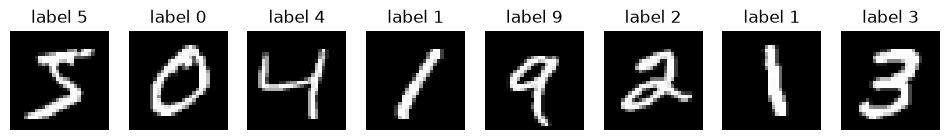

In [6]:
transform = transforms.Compose([
    transforms.ToTensor(),                       # image -> tensor with values 0..1
    transforms.Normalize((0.1307,), (0.3081,)),  # standard MNIST mean / std
])

train_full = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_full  = datasets.MNIST("./data", train=False, download=True, transform=transform)

print("Train images:", len(train_full), "| Test images:", len(test_full))

# Look at a few examples
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    img, label = train_full[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"label {label}")
    ax.axis("off")
plt.show()

## 3. Build the models

We modify ResNet a little because MNIST images are tiny and have **1 colour channel** (grey), not 3:
- `conv1`: accept 1 channel and use a small 3x3 filter (the original 7x7 is too big for 28x28 images).
- `fc` (the last layer = the "head"): set how many outputs we want.

In [7]:
def make_resnet18(num_outputs=2):
    # Specialist: ResNet18 with a 2-output head -> [not_d, d]
    model = models.resnet18(weights=None)   # weights=None -> start from random weights
    model.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.fc = nn.Linear(model.fc.in_features, num_outputs)
    return model

In [8]:
def make_resnet50(num_outputs=10):
    # Generalist: ResNet50 with a 10-output head -> one output per digit 0..9
    model = models.resnet50(weights=None)
    model.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.fc = nn.Linear(model.fc.in_features, num_outputs)
    return model

## 4. Specialist datasets ("digit d" vs "not d")

For specialist `d` we relabel MNIST:
- label **1** if the image is digit `d`
- label **0** otherwise

Example for specialist 3: an image of `3` -> 1, an image of `8` -> 0.

In [9]:
class BinaryMNIST(Dataset):
    # Wraps MNIST and changes the label to: 1 if label == digit else 0
    def __init__(self, base_dataset, digit):
        self.base = base_dataset
        self.digit = digit

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        img, label = self.base[idx]
        return img, int(label == self.digit)

In [10]:
# Use a random subset of the training data (faster). Set SPEC_TRAIN_SIZE=None for everything.
if SPEC_TRAIN_SIZE is None:
    spec_train_base = train_full
else:
    idx = np.random.permutation(len(train_full))[:SPEC_TRAIN_SIZE]
    spec_train_base = Subset(train_full, idx.tolist())

## 5. Train the 10 specialists

Problem: only ~10% of images are "digit d", 90% are "not d". A lazy model could answer "not d" every time
and be 90% correct! To avoid this we give the positive class a **bigger weight** in the loss
(mistakes on the rare class cost more).

In [11]:
def train_specialist(digit):
    model = make_resnet18(num_outputs=2).to(DEVICE)

    train_loader = DataLoader(BinaryMNIST(spec_train_base, digit),
                              batch_size=BATCH_SIZE, shuffle=True)

    # class 0 = "not d" (weight 1), class 1 = "d" (weight 9 because it is ~9x rarer)
    class_weights = torch.tensor([1.0, 9.0]).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    for epoch in range(SPEC_EPOCHS):
        model.train()
        total_loss = 0
        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            optimizer.zero_grad()              # 1) clear old gradients
            outputs = model(images)            # 2) forward pass
            loss = criterion(outputs, labels)  # 3) how wrong are we?
            loss.backward()                    # 4) compute gradients
            optimizer.step()                   # 5) update weights

            total_loss += loss.item()
        print(f"  specialist {digit} | epoch {epoch+1}/{SPEC_EPOCHS} | loss {total_loss/len(train_loader):.4f}")

    model.eval()
    torch.save(model.state_dict(), f"specialist_{digit}.pt")
    return model

In [12]:
specialists = []
for d in range(10):
    # print(f"=== Training specialist for digit {d} ===")
    specialists.append(train_specialist(d))

  specialist 0 | epoch 1/3 | loss 0.0521
  specialist 0 | epoch 2/3 | loss 0.0155
  specialist 0 | epoch 3/3 | loss 0.0129
  specialist 1 | epoch 1/3 | loss 0.0469
  specialist 1 | epoch 2/3 | loss 0.0182
  specialist 1 | epoch 3/3 | loss 0.0114
  specialist 2 | epoch 1/3 | loss 0.0894
  specialist 2 | epoch 2/3 | loss 0.0352
  specialist 2 | epoch 3/3 | loss 0.0194
  specialist 3 | epoch 1/3 | loss 0.0944
  specialist 3 | epoch 2/3 | loss 0.0353
  specialist 3 | epoch 3/3 | loss 0.0187
  specialist 4 | epoch 1/3 | loss 0.0699
  specialist 4 | epoch 2/3 | loss 0.0283
  specialist 4 | epoch 3/3 | loss 0.0190
  specialist 5 | epoch 1/3 | loss 0.0736
  specialist 5 | epoch 2/3 | loss 0.0274
  specialist 5 | epoch 3/3 | loss 0.0202
  specialist 6 | epoch 1/3 | loss 0.0587
  specialist 6 | epoch 2/3 | loss 0.0207
  specialist 6 | epoch 3/3 | loss 0.0132
  specialist 7 | epoch 1/3 | loss 0.0766
  specialist 7 | epoch 2/3 | loss 0.0277
  specialist 7 | epoch 3/3 | loss 0.0219
  specialist 8 |

## 6. Check the specialists on the test set

- **accuracy**: overall correct answers
- **recall on d**: out of all real `d` images, how many did the specialist find?

In [13]:
@torch.no_grad()
def evaluate_specialist(model, digit):
    loader = DataLoader(BinaryMNIST(test_full, digit), batch_size=256)
    correct, total, pos_correct, pos_total = 0, 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        preds = model(images).argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.numel()
        pos_mask = labels == 1
        pos_correct += (preds[pos_mask] == 1).sum().item()
        pos_total += pos_mask.sum().item()
    return correct / total, pos_correct / max(pos_total, 1)

In [14]:
for d, m in enumerate(specialists):
    acc, recall = evaluate_specialist(m, d)
    print(f"Specialist {d}: accuracy {acc*100:.2f}% | recall on digit {d}: {recall*100:.2f}%")

Specialist 0: accuracy 99.62% | recall on digit 0: 99.69%
Specialist 1: accuracy 99.79% | recall on digit 1: 99.56%
Specialist 2: accuracy 99.56% | recall on digit 2: 99.32%
Specialist 3: accuracy 97.62% | recall on digit 3: 99.90%
Specialist 4: accuracy 99.30% | recall on digit 4: 99.49%
Specialist 5: accuracy 99.76% | recall on digit 5: 98.54%
Specialist 6: accuracy 98.59% | recall on digit 6: 98.96%
Specialist 7: accuracy 99.57% | recall on digit 7: 98.74%
Specialist 8: accuracy 96.44% | recall on digit 8: 99.90%
Specialist 9: accuracy 98.66% | recall on digit 9: 87.02%


### Bonus sanity check: do the 10 specialists work as a team?

Each specialist gives a probability "I think it is my digit". We pick the specialist with the highest probability.
If the team is good, this behaves like a normal 10-class digit classifier.

In [15]:
@torch.no_grad()
def specialists_predict(images):
    # images: (B, 1, 28, 28) -> returns (B, 10): probability that each digit is present
    probs = []
    for m in specialists:
        m.eval()
        p = F.softmax(m(images), dim=1)[:, 1]   # index 1 = "it is digit d"
        probs.append(p)
    return torch.stack(probs, dim=1)

In [16]:
loader = DataLoader(test_full, batch_size=256)
correct = 0
for images, labels in loader:
    images, labels = images.to(DEVICE), labels.to(DEVICE)
    correct += (specialists_predict(images).argmax(dim=1) == labels).sum().item()
print(f"Team of specialists, 10-class accuracy: {correct/len(test_full)*100:.2f}%")

Team of specialists, 10-class accuracy: 97.73%


## 7. Stacked two-digit dataset (for the generalist)

We glue two random MNIST images **side by side** -> one image of size 28 x 56.

The label is a vector of 10 numbers (**multi-hot**):
- `[0,0,0,0,0,0,0,1,0,1]` means "digit 7 and digit 9 are present".
- If both digits are the same (e.g. 4 and 4) only one position is 1.

In [17]:
class StackedMNIST(Dataset):
    def __init__(self, base_dataset, n_samples, seed):
        self.base = base_dataset
        rng = np.random.RandomState(seed)
        # Pick which two MNIST images to overlay for every sample (fixed once, so it is repeatable)
        self.left_idx  = rng.randint(0, len(base_dataset), n_samples)
        self.right_idx = rng.randint(0, len(base_dataset), n_samples)

    def __len__(self):
        return len(self.left_idx)

    def __getitem__(self, i):
        img_a, lab_a = self.base[int(self.left_idx[i])]
        img_b, lab_b = self.base[int(self.right_idx[i])]

        # Superimpose the two digits on the same canvas -> (1, 28, 28)
        # max keeps both strokes at full brightness where they cross
        stacked = torch.maximum(img_a, img_b)

        target = torch.zeros(10)                     # multi-hot label
        target[lab_a] = 1.0
        target[lab_b] = 1.0
        return stacked, target, torch.tensor([lab_a, lab_b]), img_a, img_b
        # return stacked, target, torch.tensor([lab_a, lab_b])

In [18]:
stack_train = StackedMNIST(train_full, STACK_TRAIN_SAMPLES, seed=1)
stack_test  = StackedMNIST(test_full,  STACK_TEST_SAMPLES,  seed=2)

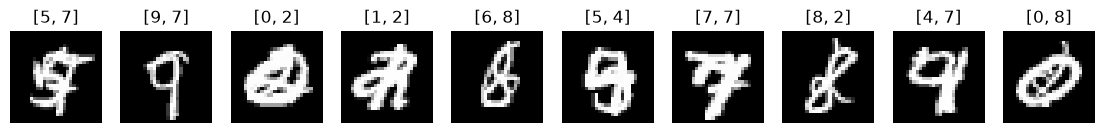

In [19]:
# Look at random examples (re-run the cell to see new ones)
idxs = random.sample(range(len(stack_train)), 10)

fig, axes = plt.subplots(1, 10, figsize=(14, 2.5))
for idx, ax in zip(idxs, axes):
    x, target, digits, img_a, img_b = stack_train[idx]
    ax.imshow(x.squeeze(), cmap="gray")
    ax.set_title(f"{digits.tolist()}")
    ax.axis("off")
plt.show()

## 8. Transfer learning: specialists teach the generalist

For every stacked image during training:
1. Cut it into **left half** and **right half** (each is a normal 28x28 digit).
2. Ask all 10 specialists about each half -> probabilities like `[0.01, 0.02, ..., 0.99, ...]`.
3. Combine the two halves with `max`: digit `d` is "present" if the left **or** right half looks like `d`.
   This is the **teacher hint** (a "soft label").
4. The generalist only sees the **whole stacked image** (it must learn to find both digits by itself).

**Loss = loss on true labels + ALPHA x loss on teacher hints.**

In [20]:
@torch.no_grad()
def teacher_targets(stacked_images):
    # stacked_images: (B, 1, 28, 56) -> teacher hint (B, 10)
    left  = stacked_images[:, :, :, :28]    # left digit
    right = stacked_images[:, :, :, 28:]    # right digit
    p_left  = specialists_predict(left)
    p_right = specialists_predict(right)
    return torch.maximum(p_left, p_right)   # digit present if EITHER half looks like it

In [21]:

generalist = make_resnet50(num_outputs=10).to(DEVICE)

train_loader = DataLoader(stack_train, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(stack_test,  batch_size=BATCH_SIZE)

# BCEWithLogitsLoss = "each of the 10 outputs is its own yes/no question" (multi-label)
bce = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(generalist.parameters(), lr=1e-3)

## 9. Train the generalist

In [22]:
def train_generalist(model,saveFile):
    for epoch in range(GEN_EPOCHS):
        model.train()
        # run_hard, run_soft = 0.0, 0.0 # gajadi pake hard label
        run_soft = 0.0

        # for images, targets, _ in train_loader:
        for images, targets, _, img_a, img_b in train_loader:
            # images, targets = images.to(DEVICE), targets.to(DEVICE) # gajadi pake hard label
            images = images.to(DEVICE)

            logits = model(images)                      # 10 raw score

            # loss_hard = bce(logits, targets)          # learn from the TRUE labels gajadi hard label
            # if ALPHA > 0:
            #     # soft = teacher_targets(images)        # hints from the specialists
            #     soft = torch.maximum(specialists_predict(img_a.to(DEVICE)), specialists_predict(img_b.to(DEVICE)))
            #     loss_soft = bce(logits, soft)           # learn from the TEACHERS
            # else:
            #     loss_soft = torch.tensor(0.0, device=DEVICE)

            with torch.no_grad():
                soft = torch.maximum(
                    specialists_predict(img_a.to(DEVICE)),
                    specialists_predict(img_b.to(DEVICE)),
                )
                soft = (soft >= 0.5).float()   # 0.9, 0.8 -> 1 ; 0.1, 0.2 -> 0

            # loss = loss_hard + ALPHA * loss_soft # gajadi hard label
            loss_soft = bce(logits, soft) 

            run_soft += loss_soft.item()

            loss = loss_soft
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # run_hard += loss_hard.item()
           

        n = len(train_loader)
        # print(f"Epoch {epoch+1}/{GEN_EPOCHS} | true-label loss {run_hard/n:.4f} | teacher loss {run_soft/n:.4f}")
        print(f"Epoch {epoch+1}/{GEN_EPOCHS} | teacher loss {run_soft/n:.4f}")

    torch.save(model.state_dict(), saveFile)

In [23]:
GEN_EPOCHS = 7
train_generalist(model=generalist, saveFile="generalist_resnet50.pt")

Epoch 1/7 | teacher loss 0.2200
Epoch 2/7 | teacher loss 0.1262
Epoch 3/7 | teacher loss 0.1019
Epoch 4/7 | teacher loss 0.0860
Epoch 5/7 | teacher loss 0.0736
Epoch 6/7 | teacher loss 0.0645
Epoch 7/7 | teacher loss 0.0584


## 10. Evaluate the generalist

Compare the existing threshold rules with the two-pass Pareto method below.
- **Exact match**: the predicted set of digits equals the true set (e.g. exactly {7, 9}).
- **Per-digit accuracy**: how often each single yes/no answer is right.

In [24]:
@torch.no_grad()
def evaluate_generalist_thresh_05(model, loader):
    model.eval()
    exact, total = 0, 0
    per_digit_correct = torch.zeros(10)
    for images, targets, *_ in loader:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        preds = (torch.sigmoid(model(images)) > 0.5).float()

        exact += (preds == targets).all(dim=1).sum().item()
        per_digit_correct += (preds == targets).float().sum(dim=0).cpu()
        total += targets.size(0)

    print(f"Exact match (both digits found, nothing extra): {exact/total*100:.2f}%")
    for d in range(10):
        print(f"  digit {d} yes/no accuracy: {per_digit_correct[d].item()/total*100:.2f}%")

In [25]:
@torch.no_grad()
def evaluate_generalist_thresh_gap(model, loader):
    model.eval()
    exact, total = 0, 0
    per_digit_correct = torch.zeros(10)
    for images, targets, *_ in loader:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        
        probs = torch.sigmoid(model(images))
        sorted_p, idx = probs.sort(dim=1, descending=True)
        gaps = sorted_p[:, :-1] - sorted_p[:, 1:]
        k = gaps.argmax(dim=1) + 1                      # digits to keep, per image
        rank = torch.arange(10, device=DEVICE).unsqueeze(0)
        keep = (rank < k.unsqueeze(1)).float()          # 1 for the top-k ranks
        preds = torch.zeros_like(probs).scatter_(1, idx, keep)

        exact += (preds == targets).all(dim=1).sum().item()
        per_digit_correct += (preds == targets).float().sum(dim=0).cpu()
        total += targets.size(0)

    print(f"Exact match (both digits found, nothing extra): {exact/total*100:.2f}%")
    for d in range(10):
        print(f"  digit {d} yes/no accuracy: {per_digit_correct[d].item()/total*100:.2f}%")

In [26]:
# @torch.no_grad()
# def evaluate_generalist_thresh_relative_max(model, loader):
#     model.eval()
#     exact, total = 0, 0
#     per_digit_correct = torch.zeros(10)
#     for images, targets, *_ in loader:
#         images, targets = images.to(DEVICE), targets.to(DEVICE)
#         probs = torch.sigmoid(model(x.unsqueeze(0).to(DEVICE)))[0].cpu()
#         preds = [d for d in range(10) if probs[d] > 0.5 * probs.max()]

#         exact += (preds == targets).all(dim=1).sum().item()
#         per_digit_correct += (preds == targets).float().sum(dim=0).cpu()
#         total += targets.size(0)

#     print(f"Exact match (both digits found, nothing extra): {exact/total*100:.2f}%")
#     for d in range(10):
#         print(f"  digit {d} yes/no accuracy: {per_digit_correct[d].item()/total*100:.2f}%")
@torch.no_grad()
def evaluate_generalist_thresh_relative_max(model, loader, ratio=0.5):
    model.eval()
    exact, total = 0, 0
    per_digit_correct = torch.zeros(10)
    for images, targets, *_ in loader:
        images, targets = images.to(DEVICE), targets.to(DEVICE)

        probs = torch.sigmoid(model(images))                         # (batch, 10)
        max_p = probs.max(dim=1, keepdim=True).values                # (batch, 1) max per image
        preds = (probs > ratio * max_p).float()                      # (batch, 10) of 0/1

        exact += (preds == targets).all(dim=1).sum().item()
        per_digit_correct += (preds == targets).float().sum(dim=0).cpu()
        total += targets.size(0)

    print(f"Exact match: {exact/total*100:.2f}%")
    for d in range(10):
        print(f"  digit {d} yes/no accuracy: {per_digit_correct[d].item()/total*100:.2f}%")

In [27]:
@torch.no_grad()
def evaluate_generalist_thresh_relative_max_norm(model, loader, ratio=0.1):
    model.eval()
    exact, total = 0, 0
    per_digit_correct = torch.zeros(10)
    for images, targets, *_ in loader:
        images, targets = images.to(DEVICE), targets.to(DEVICE)

        probs = torch.sigmoid(model(images))                         
        
        # 1. Hitung nilai min dan max untuk setiap gambar
        min_p = probs.min(dim=1, keepdim=True).values                
        max_p = probs.max(dim=1, keepdim=True).values                
        
        # 2. Normalisasi ke rentang [0, 1] (ditambah 1e-8 untuk menghindari pembagian dengan nol)
        norm_probs = (probs - min_p) / (max_p - min_p + 1e-8)        
        
        # 3. Terapkan threshold statis pada probabilitas yang sudah dinormalisasi
        preds = (norm_probs > ratio).float()                         

        exact += (preds == targets).all(dim=1).sum().item()
        per_digit_correct += (preds == targets).float().sum(dim=0).cpu()
        total += targets.size(0)

    print(f"Exact match: {exact/total*100:.2f}%")
    for d in range(10):
        print(f"  digit {d} yes/no accuracy: {per_digit_correct[d].item()/total*100:.2f}%")

### Two Pareto passes with a shifted-image recheck

1. Normalize the generalist's 10 sigmoid scores by their sum. Sort descending and keep
   the smallest set reaching at least **95% cumulative mass**, including the crossing class.
2. Re-evaluate the same overlaid image shifted one pixel left and right, using normalized
   black-background padding. Average the three sets of raw sigmoid scores.
3. Discard classes excluded by the first pass, renormalize survivors, and select 95% again.

`PARETO_MASS` controls both passes. This is cumulative score mass, not a statistical
confidence interval or a guarantee of 95% accuracy. The final set can cover less than
95% of the original scores. Eliminated classes cannot return. The recheck uses three
model evaluations in total and needs no retraining or access to the separate digit images.

Evaluation compares both passes on the same samples. Precision and recall are micro-averaged
across all digit decisions; average selected digits shows how much the second pass prunes.


In [ ]:
# PARETO_MASS = 0.85


def pareto_mask(probs, mass=PARETO_MASS):
    """Select the smallest sorted prefix reaching mass, independently per image.

    probs: nonnegative scores of shape (batch, classes).
    Returns a boolean mask in the original class order; zero rows select nothing.
    """
    if not 0.0 < mass <= 1.0:
        raise ValueError("mass must be in (0, 1]")
    if probs.ndim != 2:
        raise ValueError("probs must have shape (batch, classes)")
    if mass == 1.0:
        return probs > 0

    total = probs.sum(dim=1, keepdim=True)
    normalized = probs / torch.where(total > 0, total, torch.ones_like(total))
    sorted_p, indices = normalized.sort(dim=1, descending=True, stable=True)
    cumulative = sorted_p.cumsum(dim=1)
    # Keep the class that reaches/crosses the cutoff; exclude zero-score classes.
    before = F.pad(cumulative[:, :-1], (1, 0), value=0.0)
    keep = (before < mass) & (sorted_p > 0)
    return torch.zeros_like(probs, dtype=torch.bool).scatter_(1, indices, keep)


@torch.no_grad()
def predict_generalist_pareto(model, images, mass=PARETO_MASS):
    """Return (first-pass mask, final mask) using three generalist evaluations."""
    model.eval()
    original_probs = torch.sigmoid(model(images))
    first_pass = pareto_mask(original_probs, mass)

    # Black background after the MNIST normalization used in section 2.
    background = -0.1307 / 0.3081
    padded = F.pad(images, (1, 1, 0, 0), value=background)
    left_probs = torch.sigmoid(model(padded[..., 2:]))    # one pixel left
    right_probs = torch.sigmoid(model(padded[..., :-2]))  # one pixel right

    # Average raw sigmoid scores BEFORE renormalizing surviving candidates.
    updated_probs = (original_probs + left_probs + right_probs) / 3.0
    surviving_probs = updated_probs.masked_fill(~first_pass, 0.0)
    final = pareto_mask(surviving_probs, mass)
    return first_pass, final


In [49]:
@torch.no_grad()
def evaluate_generalist_pareto(model, loader, mass=PARETO_MASS):
    model.eval()
    stages = ("First Pareto pass", "Second Pareto pass + shifted views")
    stats = {
        name: dict(exact=0, tp=0, fp=0, fn=0, selected=0,
                   per_digit_correct=torch.zeros(10))
        for name in stages
    }
    total = 0
    for images, targets, *_ in loader:
        images = images.to(DEVICE)
        targets = targets.to(DEVICE).bool()
        first_pass, final = predict_generalist_pareto(model, images, mass)
        total += targets.size(0)
        for name, preds in zip(stages, (first_pass, final)):
            s = stats[name]
            s["exact"] += (preds == targets).all(dim=1).sum().item()
            s["per_digit_correct"] += (preds == targets).sum(dim=0).cpu()
            s["tp"] += (preds & targets).sum().item()
            s["fp"] += (preds & ~targets).sum().item()
            s["fn"] += (~preds & targets).sum().item()
            s["selected"] += preds.sum().item()

    if total == 0:
        raise ValueError("The evaluation loader is empty")
    results = {}
    for name, s in stats.items():
        results[name] = {
            "exact_match": s["exact"] / total,
            "precision": s["tp"] / max(s["tp"] + s["fp"], 1),
            "recall": s["tp"] / max(s["tp"] + s["fn"], 1),
            "mean_digits": s["selected"] / total,
            "per_digit_accuracy": (s["per_digit_correct"] / total).tolist(),
        }
        r = results[name]
        print(f"{name} (cumulative mass={mass:.0%})")
        print(f"  Exact match: {r['exact_match']:.2%} | "
              f"Precision: {r['precision']:.2%} | Recall: {r['recall']:.2%}")
        print(f"  Average selected digits: {r['mean_digits']:.2f}")
        for d, accuracy in enumerate(r["per_digit_accuracy"]):
            print(f"  digit {d} yes/no accuracy: {accuracy:.2%}")
    return results


In [30]:
evaluate_generalist_thresh_05(model=generalist, loader=test_loader)

Exact match (both digits found, nothing extra): 76.02%
  digit 0 yes/no accuracy: 98.72%
  digit 1 yes/no accuracy: 97.50%
  digit 2 yes/no accuracy: 97.40%
  digit 3 yes/no accuracy: 96.06%
  digit 4 yes/no accuracy: 97.04%
  digit 5 yes/no accuracy: 96.94%
  digit 6 yes/no accuracy: 96.70%
  digit 7 yes/no accuracy: 96.40%
  digit 8 yes/no accuracy: 94.96%
  digit 9 yes/no accuracy: 94.72%


In [31]:
evaluate_generalist_thresh_gap(model=generalist, loader=test_loader)

Exact match (both digits found, nothing extra): 75.00%
  digit 0 yes/no accuracy: 98.70%
  digit 1 yes/no accuracy: 97.60%
  digit 2 yes/no accuracy: 97.42%
  digit 3 yes/no accuracy: 95.86%
  digit 4 yes/no accuracy: 97.00%
  digit 5 yes/no accuracy: 97.00%
  digit 6 yes/no accuracy: 96.66%
  digit 7 yes/no accuracy: 96.18%
  digit 8 yes/no accuracy: 95.02%
  digit 9 yes/no accuracy: 94.78%


In [32]:
evaluate_generalist_thresh_relative_max(model=generalist, loader=test_loader)

Exact match: 75.96%
  digit 0 yes/no accuracy: 98.68%
  digit 1 yes/no accuracy: 97.48%
  digit 2 yes/no accuracy: 97.38%
  digit 3 yes/no accuracy: 96.00%
  digit 4 yes/no accuracy: 97.02%
  digit 5 yes/no accuracy: 96.98%
  digit 6 yes/no accuracy: 96.66%
  digit 7 yes/no accuracy: 96.38%
  digit 8 yes/no accuracy: 94.90%
  digit 9 yes/no accuracy: 94.76%


In [33]:
evaluate_generalist_thresh_relative_max_norm(model=generalist, loader=test_loader)

Exact match: 63.24%
  digit 0 yes/no accuracy: 97.94%
  digit 1 yes/no accuracy: 95.22%
  digit 2 yes/no accuracy: 95.74%
  digit 3 yes/no accuracy: 91.84%
  digit 4 yes/no accuracy: 95.08%
  digit 5 yes/no accuracy: 96.94%
  digit 6 yes/no accuracy: 91.48%
  digit 7 yes/no accuracy: 94.44%
  digit 8 yes/no accuracy: 89.86%
  digit 9 yes/no accuracy: 95.80%


In [63]:
PARETO_MASS = 0.70

pareto_results = evaluate_generalist_pareto(model=generalist, loader=test_loader, mass=PARETO_MASS)


First Pareto pass (cumulative mass=70%)
  Exact match: 79.42% | Precision: 90.50% | Recall: 92.13%
  Average selected digits: 1.93
  digit 0 yes/no accuracy: 98.56%
  digit 1 yes/no accuracy: 97.26%
  digit 2 yes/no accuracy: 97.54%
  digit 3 yes/no accuracy: 96.00%
  digit 4 yes/no accuracy: 96.96%
  digit 5 yes/no accuracy: 97.00%
  digit 6 yes/no accuracy: 96.78%
  digit 7 yes/no accuracy: 96.18%
  digit 8 yes/no accuracy: 95.24%
  digit 9 yes/no accuracy: 95.22%
Second Pareto pass + shifted views (cumulative mass=70%)
  Exact match: 80.50% | Precision: 93.08% | Recall: 90.74%
  Average selected digits: 1.85
  digit 0 yes/no accuracy: 98.64%
  digit 1 yes/no accuracy: 97.72%
  digit 2 yes/no accuracy: 97.70%
  digit 3 yes/no accuracy: 96.68%
  digit 4 yes/no accuracy: 97.12%
  digit 5 yes/no accuracy: 96.92%
  digit 6 yes/no accuracy: 97.68%
  digit 7 yes/no accuracy: 96.52%
  digit 8 yes/no accuracy: 95.98%
  digit 9 yes/no accuracy: 94.68%


## 11. See predictions

In [35]:
@torch.no_grad()
def show_predictions(model, n=8):
    model.eval()
    fig, axes = plt.subplots(1, n, figsize=(2.2 * n, 3))
    for ax in axes:
        i = random.randrange(len(stack_test))
        x, target, digits, img_a, img_b = stack_test[i]     # x is the overlaid (1, 28, 28) image

        probs = torch.sigmoid(model(x.unsqueeze(0).to(DEVICE)))[0].cpu()
        predicted = [d for d in range(10) if probs[d] > 0.5]
        true = sorted(set(digits.tolist()))

        ax.imshow(x.squeeze(), cmap="gray")
        ax.set_title(f"true {true}\npred {predicted}",
                     color="green" if predicted == true else "red")
        ax.axis("off")
    plt.show()

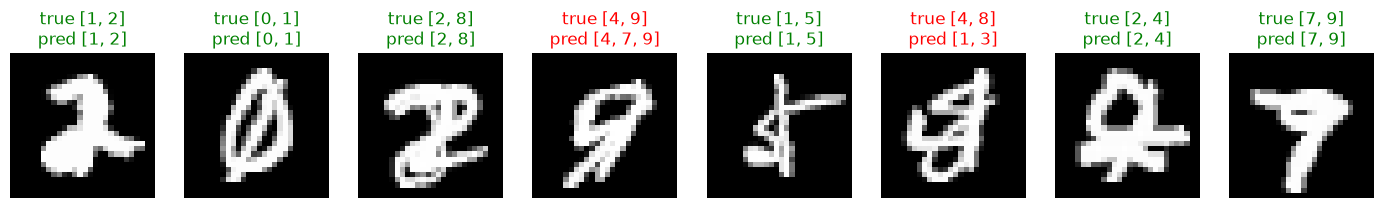

In [36]:
show_predictions(model=generalist)

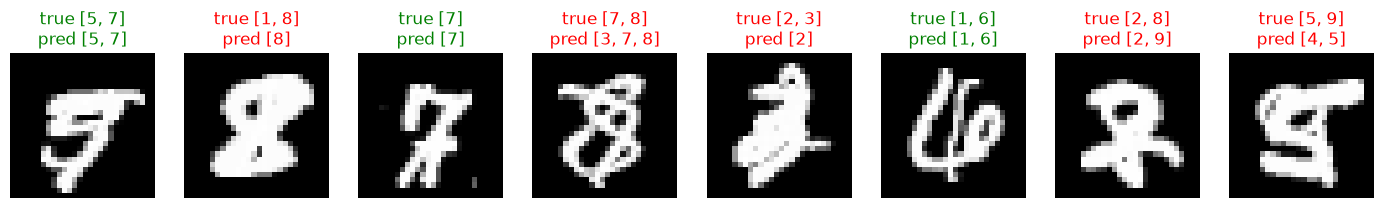

In [37]:
show_predictions(model=generalist)

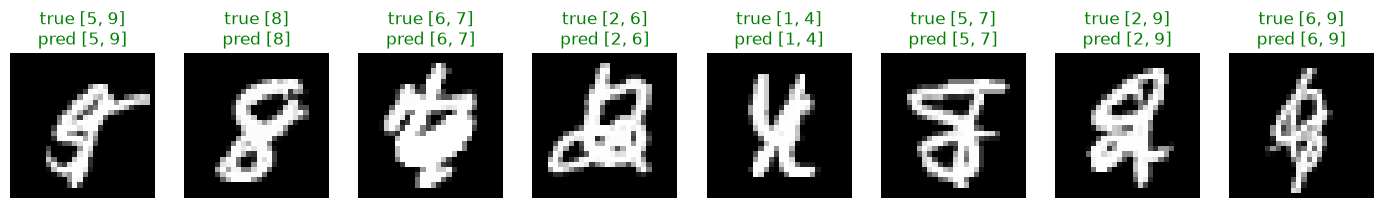

In [38]:
show_predictions(model=generalist)

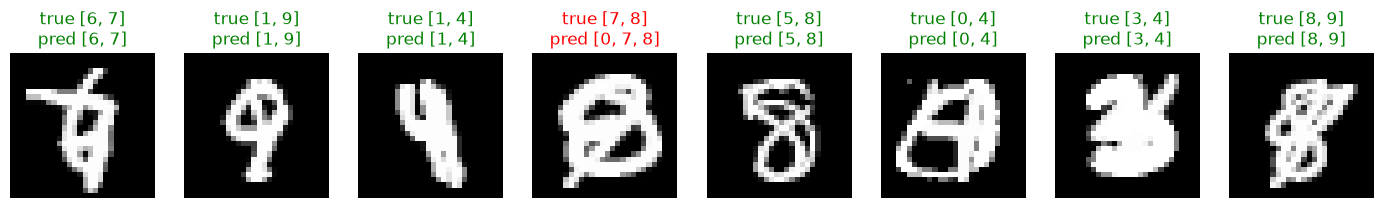

In [39]:
show_predictions(model=generalist)

In [40]:
# @torch.no_grad()
# def show_predictions_gap(model, n=2):
#     model.eval()
#     fig, axes = plt.subplots(1, n, figsize=(2.2 * n, 3))
#     for ax in axes:
#         i = random.randrange(len(stack_test))
#         x, target, digits, img_a, img_b = stack_test[i]     # x is the overlaid (1, 28, 28) image

#         probs = torch.sigmoid(model(images))
#         sorted_p, idx = probs.sort(dim=1, descending=True)
#         gaps = sorted_p[:, :-1] - sorted_p[:, 1:]
#         k = gaps.argmax(dim=1) + 1                      # digits to keep, per image
#         rank = torch.arange(10, device=DEVICE).unsqueeze(0)
#         keep = (rank < k.unsqueeze(1)).float()          # 1 for the top-k ranks
#         preds = torch.zeros_like(probs).scatter_(1, idx, keep)
#         predicted = [d for d in range(10) if probs[d] > 0.5]
#         true = sorted(set(digits.tolist()))

#         ax.imshow(x.squeeze(), cmap="gray")
#         ax.set_title(f"true {true}\npred {predicted}",
#                      color="green" if predicted == true else "red")
#         ax.axis("off")
#     plt.show()
@torch.no_grad()
def show_predictions_gap(model, n=8):
    model.eval()
    fig, axes = plt.subplots(1, n, figsize=(2.2 * n, 3))
    for ax in axes:
        i = random.randrange(len(stack_test))
        x, target, digits, img_a, img_b = stack_test[i]

        probs = torch.sigmoid(model(x.unsqueeze(0).to(DEVICE)))[0].cpu()   # (10,)

        sorted_p, idx = probs.sort(descending=True)
        gaps = sorted_p[:-1] - sorted_p[1:]
        k = gaps.argmax().item() + 1                  # number of digits to keep
        predicted = sorted(idx[:k].tolist())          # the top-k digits

        true = sorted(set(digits.tolist()))

        ax.imshow(x.squeeze(), cmap="gray")
        ax.set_title(f"true {true}\npred {predicted}",
                     color="green" if predicted == true else "red")
        ax.axis("off")
    plt.show()

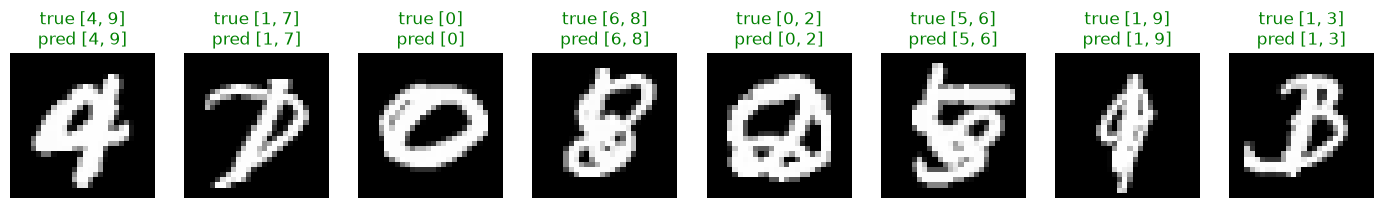

In [41]:
show_predictions_gap(model=generalist)

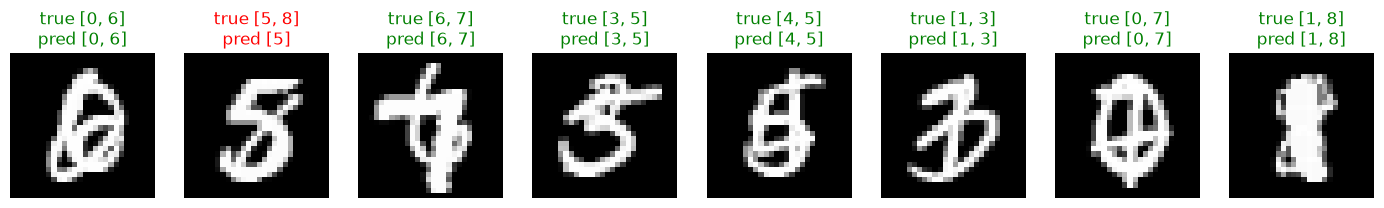

In [42]:
show_predictions_gap(model=generalist)

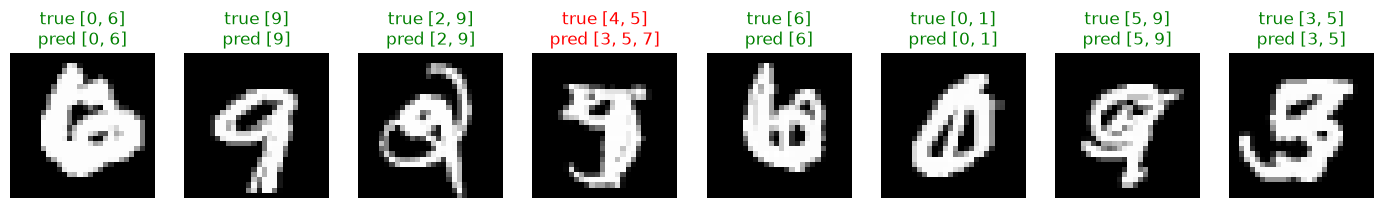

In [43]:
show_predictions_gap(model=generalist)

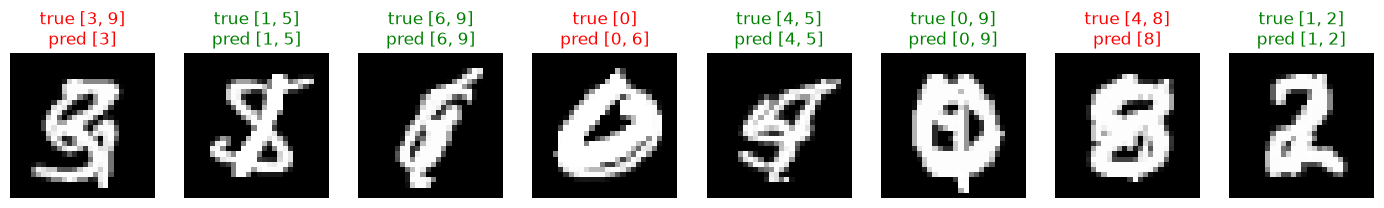

In [44]:
show_predictions_gap(model=generalist)

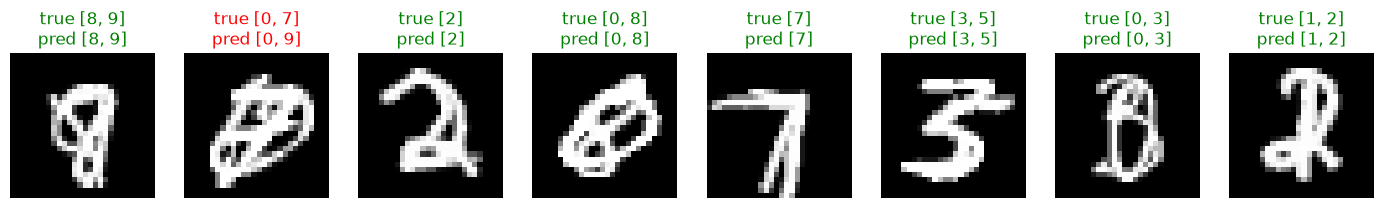

In [45]:
show_predictions_gap(model=generalist)

### See the first and second Pareto selections

Each image shows the true digits and both predicted sets.


In [46]:
@torch.no_grad()
def show_predictions_pareto(model, n=8, mass=PARETO_MASS):
    model.eval()
    fig, axes = plt.subplots(1, n, figsize=(2.4 * n, 3), squeeze=False)
    for ax in axes.ravel():
        i = random.randrange(len(stack_test))
        x, target, digits, *_ = stack_test[i]
        first_pass, final = predict_generalist_pareto(
            model, x.unsqueeze(0).to(DEVICE), mass
        )
        first_digits = first_pass[0].nonzero(as_tuple=True)[0].cpu().tolist()
        predicted = final[0].nonzero(as_tuple=True)[0].cpu().tolist()
        true = sorted(set(digits.tolist()))

        ax.imshow(x.squeeze(), cmap="gray")
        ax.set_title(f"true {true}\npass 1 {first_digits}\npass 2 {predicted}",
                     color="green" if predicted == true else "red")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


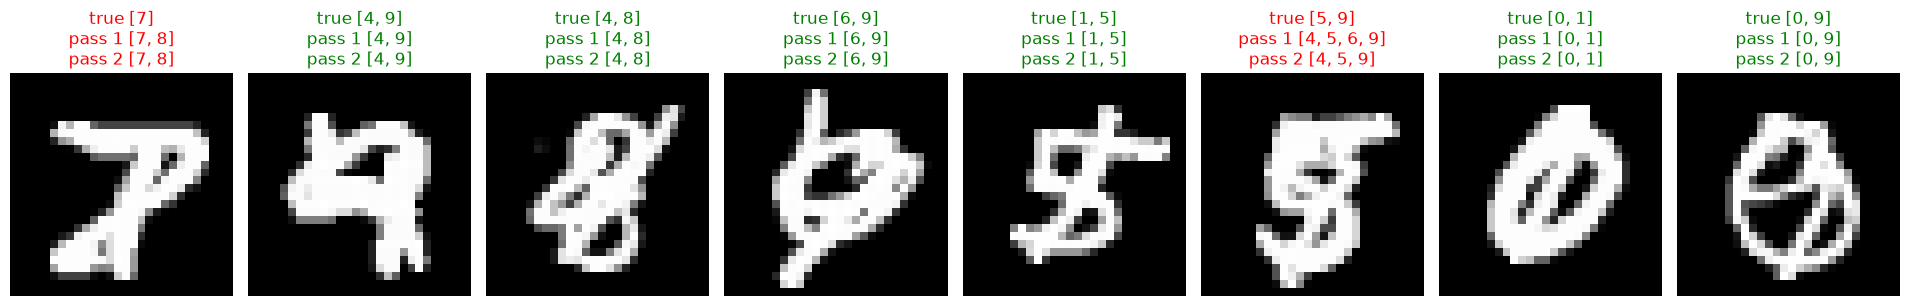

In [47]:
show_predictions_pareto(model=generalist)
